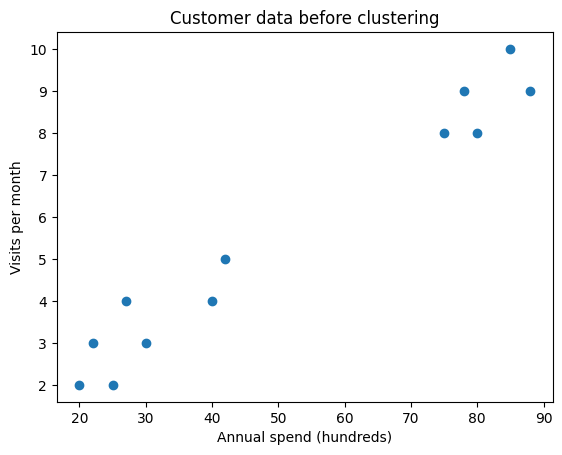

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
# Create dataset with 2 numerical features
customers = pd.DataFrame({
"AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
"VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
# Scatter plot visualization
plt.scatter(customers["AnnualSpend"],
customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()


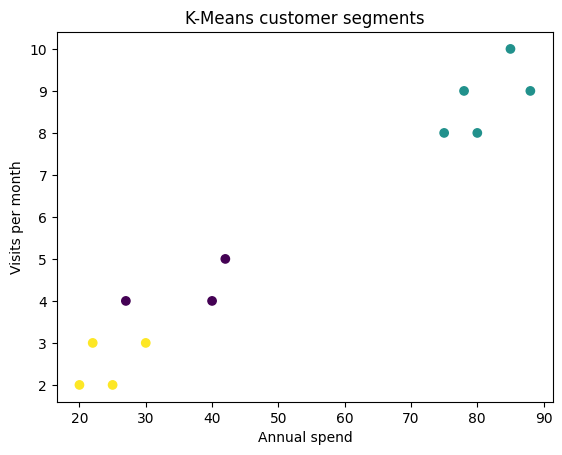

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))


2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4


Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


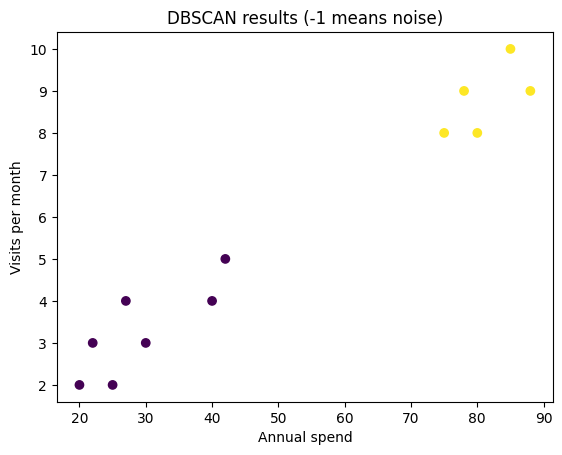

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Define the sample customer dataset
customers = pd.DataFrame({
    "AnnualSpend": [20, 22, 25, 27, 30, 75, 78, 80, 85, 88, 40, 42],
    "VisitsPerMonth": [2, 3, 2, 4, 3, 8, 9, 8, 10, 9, 4, 5]
})

# Scale the numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

# Initialize and run DBSCAN clustering
db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

# Print cluster labels and count noise points
print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

# Visualize the resulting clusters
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()


Explained variance: [0.73  0.229]


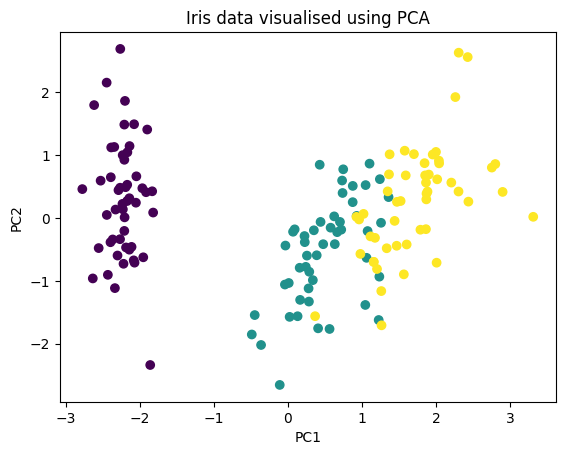

In [15]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()


In [16]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")


[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


Transaction [20  2] -> Normal
Transaction [22  3] -> Normal
Transaction [18  2] -> Normal
Transaction [25  3] -> Normal
Transaction [21  2] -> Normal
Transaction [23  4] -> Normal
Transaction [19  3] -> Normal
Transaction [250  20] -> Anomaly
--- Cluster-wise Average Annual Spending (K=3) ---
Cluster_K3
0    36.33
1    81.20
2    24.25
Name: AnnualSpend, dtype: float64

--- Metric Comparison across K values ---
K=2 | Inertia: 2.03 | Silhouette Score: 0.786
K=3 | Inertia: 0.97 | Silhouette Score: 0.591
K=4 | Inertia: 0.66 | Silhouette Score: 0.449

--- DBSCAN Results (-1 represents noise/outliers) ---
    AnnualSpend  VisitsPerMonth  DBSCAN_Cluster
0            20               2               0
1            22               3               0
2            25               2               0
3            27               4               0
4            30               3               0
5            75               8               1
6            78               9               1
7       

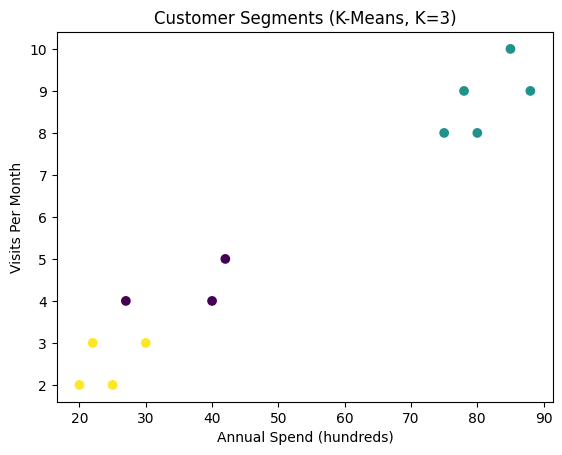

In [17]:


### 1\. Code for Slide 26 (Anomaly Detection using Isolation Forest)




import numpy as np
from sklearn.ensemble import IsolationForest

# Sample transaction data [amount, frequency]
transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

# Initialize Isolation Forest with expected contamination rate
detector = IsolationForest(contamination=0.12, random_state=42)

# Fit model and predict anomaly labels (-1 = Anomaly, 1 = Normal)
labels = detector.fit_predict(transactions)

# Print classification results
for row, label in zip(transactions, labels):
    status = "Anomaly" if label == -1 else "Normal"
    print(f"Transaction {row} -> {status}")



### 2\. Code for Slide 27 (Practical 2: Customer Segmentation Task)


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Step 1: Define the customer dataset
customers = pd.DataFrame({
    "AnnualSpend": [20, 22, 25, 27, 30, 75, 78, 80, 85, 88, 40, 42],
    "VisitsPerMonth": [2, 3, 2, 4, 3, 8, 9, 8, 10, 9, 4, 5]
})

# Step 2: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

# Step 3: Run K-Means with K=3 & calculate cluster averages
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster_K3"] = kmeans3.fit_predict(X_scaled)

print("--- Cluster-wise Average Annual Spending (K=3) ---")
print(customers.groupby("Cluster_K3")["AnnualSpend"].mean().round(2))

# Step 4: Compare K=2, K=3, and K=4 (Elbow & Silhouette)
print("\n--- Metric Comparison across K values ---")
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, lbls)
    print(f"K={k} | Inertia: {km.inertia_:.2f} | Silhouette Score: {sil:.3f}")

# Step 5: DBSCAN Clustering
db = DBSCAN(eps=0.8, min_samples=2)
customers["DBSCAN_Cluster"] = db.fit_predict(X_scaled)

print("\n--- DBSCAN Results (-1 represents noise/outliers) ---")
print(customers[["AnnualSpend", "VisitsPerMonth", "DBSCAN_Cluster"]])

# Visualization of K-Means (K=3)
plt.scatter(customers["AnnualSpend"], customers["VisitsPerMonth"], c=customers["Cluster_K3"], cmap="viridis")
plt.xlabel("Annual Spend (hundreds)")
plt.ylabel("Visits Per Month")
plt.title("Customer Segments (K-Means, K=3)")
plt.show()


